---

# Conference Popularity and Association Pattern Mining pada Dataset DBLP

*Notebook 02: Task 3, Transactional Database Construction.*

---

## Kelompok Tugas Besar Data Mining

- Izhar Alif Akbar (18223129)
- Harfhan Ikhtiar (18223123)
- Mahesa Andre (13523140)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Pembentukan Transactional Database (Task 3.1)**](#3)
4. [**Contoh Transaksi (Task 3.2)**](#4)
5. [**Statistik Transactional Database (Task 3.3 dan 3.4)**](#5)
6. [**Perbandingan dan Analisis (Task 3.5 dan 3.6)**](#6)
7. [**Ringkasan dan Langkah Berikutnya**](#7)

---

# Introduction <a name="1"></a>

---

## Overview

*Task 3 mengubah dataset DBLP yang sudah bersih menjadi transactional database, yaitu bentuk data yang dibutuhkan algoritma Frequent Pattern Mining. Dua representasi dibentuk dari tabel pasangan paper-author hasil Task 1. Pada representasi author-based, satu transaksi mewakili satu author. Pada representasi author-year-based, satu transaksi mewakili satu kombinasi author dan tahun. Item pada kedua representasi adalah venue, yaitu konferensi tempat author menerbitkan paper.*

*Notebook ini adalah notebook ketiga pada alur proyek: `00_extract` untuk ekstraksi, `01_eda` untuk Task 1 dan Task 2, dan `02_transactions` untuk Task 3. Algoritma Apriori dan FP-Growth dikerjakan pada notebook terpisah agar setiap tahap mudah diperiksa dan diulang.*

## Aim

*Task 3.1: membentuk dua transactional database, yaitu author-based dan author-year-based.*

*Task 3.2 dan 3.3: menampilkan minimal 10 contoh transaksi dari setiap representasi dan menghitung jumlah transaksinya.*

*Task 3.4: menghitung jumlah item unik dan distribusi jumlah item per transaksi.*

*Task 3.5 dan 3.6: menganalisis perbedaan kedua representasi, lalu menjelaskan kelebihan dan keterbatasan masing-masing untuk Frequent Pattern Mining.*

## Metric

***Support** sebuah itemset $X$ adalah proporsi transaksi yang memuat seluruh item pada $X$. Ukuran ini dipakai untuk menentukan item yang frequent pada bagian statistik, dan menjadi dasar Task 4.*

$$\text{support}(X) = \frac{|\{t \in D : X \subseteq t\}|}{|D|}$$

***Beban kombinasi** menghitung banyaknya pasangan item yang dapat dibentuk dari seluruh transaksi. Transaksi berisi $k$ item menghasilkan $\binom{k}{2}$ pasangan, sehingga transaksi besar sangat memengaruhi waktu proses algoritma yang membangkitkan kombinasi.*

$$B = \sum_{t \in D} \binom{|t|}{2}$$

## Dataset

*Data berasal dari `data/processed/paper_author.parquet`, hasil preprocessing pada notebook `01_eda`. Tabel ini memuat 7.870.902 pasangan paper-author dari 1.997.244 paper DBLP periode 2015-2025 (https://dblp.org/xml/).*

*Dataset dipakai untuk membentuk transaksi yang menyatakan konferensi tempat setiap author pernah atau sedang menerbitkan paper.*

**Attributes**

1.  `key`     : ID unik paper
2.  `year`    : tahun publikasi
3.  `venue`   : konferensi (seri), diturunkan dari segmen kedua `key`
4.  `author`  : nama author setelah normalisasi

**Target**

Transaksi berupa himpunan venue. Satu transaksi adalah satu author (author-based) atau satu pasangan author dan tahun (author-year-based).

## Approach: Satu Sumber, Dua Bentuk Penyimpanan

*Kedua database dibentuk dari satu tabel panjang berisi pasangan `tid` (id transaksi) dan `item` (kode venue). Tabel panjang inilah sumber kebenaran dan disimpan ke disk. Dari tabel itu dibentuk dua bentuk penyimpanan di memori. Bentuk horizontal berupa list of frozenset dipakai oleh Apriori dan FP-Growth. Bentuk sparse berupa matriks transaksi dan item dipakai untuk statistik dan validasi dengan `mlxtend`.*

*Kedua bentuk berisi informasi yang sama persis dan hanya berbeda cara penyimpanannya, sehingga hasil pembentukannya dicocokkan dengan pemeriksaan eksplisit. Yang berbeda isinya adalah database author-based dan author-year-based, karena jumlah dan isi transaksinya berbeda.*

```
paper_author.parquet
    |
    +-- tabel panjang (tid, item) per database      <- disimpan, sumber kebenaran
            |
            +-- horizontal: list of frozenset       <- masukan Apriori dan FP-Growth
            +-- sparse CSR: transaksi x item        <- statistik dan validasi mlxtend
```

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini tidak memakai GPU. Seluruh sel dapat dijalankan dalam beberapa menit pada Mac dengan RAM 16 GB. Prasyaratnya adalah notebook `01_eda` sudah dijalankan sehingga `data/processed/paper_author.parquet` tersedia.

Sel berikut memasang semua pustaka yang dipakai notebook ini.

In [1]:
%pip install -q numpy pandas scipy matplotlib pyarrow

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan di satu sel.

In [2]:
import os
import random
import textwrap
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle
from matplotlib.ticker import FuncFormatter
from scipy import sparse

## Seed Everything

Pembentukan transaksi bersifat deterministik, tetapi pemilihan contoh transaksi memakai pengambilan acak. Seed ditetapkan agar contoh yang ditampilkan selalu sama.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, ambang min support, dan warna dipusatkan di kelas `Settings`. Palet warna sama dengan notebook `01_eda`: biru sebagai aksen utama, jingga untuk pembanding, dan abu-abu untuk konteks.

In [4]:
class Settings:
    SEED = 42
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    PROC_DIR = ROOT / "data" / "processed"
    TAB_DIR = ROOT / "outputs" / "tables"
    FIG_DIR = ROOT / "outputs" / "figures"

    PAPER_AUTHOR = PROC_DIR / "paper_author.parquet"
    CLEAN = PROC_DIR / "inproceedings_clean.parquet"
    VENUE_LABEL = PROC_DIR / "venue_label.csv"

    ITEMS = PROC_DIR / "tx_items.csv"
    TX_AUTHOR = PROC_DIR / "tx_author.parquet"
    TX_AUTHOR_INDEX = PROC_DIR / "tx_author_index.parquet"
    TX_AUTHOR_YEAR = PROC_DIR / "tx_author_year.parquet"
    TX_AUTHOR_YEAR_INDEX = PROC_DIR / "tx_author_year_index.parquet"

    MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]

    INK = "#0b0b0b"
    INK_2 = "#52514e"
    MUTED = "#898781"
    GRID = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"
    BLUE = "#2a78d6"
    BLUE_LIGHT = "#9ec5f4"
    ORANGE = "#eb6834"
    GRAY = "#b9b8b2"

CFG = Settings()
CFG.TAB_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)

Gaya grafik dan fungsi bantu diatur sekali di sini. Angka ditulis dengan pemisah ribuan titik dan desimal koma agar konsisten dengan notebook sebelumnya.

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": CFG.SURFACE, "axes.facecolor": CFG.SURFACE, "savefig.facecolor": CFG.SURFACE,
    "font.size": 9.5, "text.color": CFG.INK, "axes.labelcolor": CFG.INK_2,
    "xtick.color": CFG.INK_2, "ytick.color": CFG.INK_2, "axes.edgecolor": CFG.BASELINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CFG.GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)


def fmt_id(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".")


def pct_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",") + "%"


def save_fig(fig, name):
    fig.savefig(CFG.FIG_DIR / name)
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(CFG.TAB_DIR / name, index=index)


def id_ticks(ax, axis="x"):
    formatter = FuncFormatter(lambda v, _: fmt_id(v, 0 if float(v).is_integer() else 1))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)

## Load Dataset

Tabel pasangan paper-author dibaca dengan hanya tiga kolom yang dibutuhkan, yaitu `author`, `year`, dan `venue`. Ukuran paper per venue dan pemetaan nama tampilan venue juga dibaca untuk keperluan penamaan item. Tidak ada visualisasi pada tahap ini.

In [6]:
pa = pd.read_parquet(CFG.PAPER_AUTHOR, columns=["author", "year", "venue"])
venue_size = pd.read_parquet(CFG.CLEAN, columns=["venue"]).groupby("venue").size()
venue_label = pd.read_csv(CFG.VENUE_LABEL, index_col="venue")["nama_tampil"]
largest_for_label = venue_size.groupby(venue_label).idxmax()

def display_name(venue):
    label = venue_label[venue]
    return label if largest_for_label[label] == venue else f"{label} [{venue}]"

print(f"Pasangan paper-author: {len(pa):,} | author unik: {pa['author'].nunique():,} | venue unik: {pa['venue'].nunique():,}")

Pasangan paper-author: 7,870,902 | author unik: 1,821,757 | venue unik: 4,373


---

# Pembentukan Transactional Database (Task 3.1) <a name="3"></a>

---

Bagian ini menjawab Task 3.1. Kedua database dibentuk dari tabel `paper_author` dengan prosedur yang sama, dan hanya kunci pengelompokannya yang berbeda.

## 3.1 Rancangan: Grain, Item, dan Aturan

Satu baris `paper_author` adalah satu author pada satu paper. Transaksi dibentuk dengan mengelompokkan baris tersebut, lalu mengambil **himpunan venue unik** pada setiap kelompok.

| | Author-based | Author-year-based |
|---|---|---|
| Kunci pengelompokan | `author` | `author` dan `year` |
| Satu transaksi | satu orang | satu orang pada satu tahun |
| Item | venue yang pernah ia terbitkan selama 2015-2025 | venue yang ia terbitkan pada tahun itu |

Karena item adalah himpunan, dua paper di venue yang sama dalam satu transaksi hanya menghasilkan satu item. Jumlah paper tidak disimpan pada transaksi, karena support menghitung banyaknya transaksi yang memuat suatu itemset, bukan banyaknya kemunculan.

## 3.2 Tabel Panjang sebagai Sumber Kebenaran

Setiap venue diberi kode integer berdasarkan urutan alfabet `key`, sehingga kode stabil antarnotebook. Tabel panjang `(tid, item)` dibentuk dengan menghapus pasangan ganda, lalu diurutkan agar isinya deterministik. Tabel indeks memetakan `tid` kembali ke author atau pasangan author dan tahun, sehingga setiap transaksi dapat ditelusuri asalnya. Kolom `n_paper` pada tabel indeks menyimpan jumlah paper di balik setiap transaksi, karena jumlah itu tidak terbawa oleh himpunan venue.

In [7]:
items = pd.DataFrame({"venue": np.sort(pa["venue"].unique())})
items["item_id"] = np.arange(len(items), dtype=np.int32)
items["nama"] = [display_name(v) for v in items["venue"]]
item_of = dict(zip(items["venue"], items["item_id"]))
pa["item"] = pa["venue"].map(item_of).astype(np.int32)

pairs_a = pa[["author", "item"]].drop_duplicates()
pairs_a["tid"] = pd.factorize(pairs_a["author"])[0].astype(np.int32)
long_a = pairs_a[["tid", "item"]].sort_values(["tid", "item"]).reset_index(drop=True)
index_a = pairs_a.drop_duplicates("tid")[["tid", "author"]].sort_values("tid").reset_index(drop=True)

pairs_ay = pa[["author", "year", "item"]].drop_duplicates()
pairs_ay["tid"] = pairs_ay.groupby(["author", "year"], sort=False).ngroup().astype(np.int32)
long_ay = pairs_ay[["tid", "item"]].sort_values(["tid", "item"]).reset_index(drop=True)
index_ay = pairs_ay.drop_duplicates("tid")[["tid", "author", "year"]].sort_values("tid").reset_index(drop=True)
index_ay["year"] = index_ay["year"].astype(np.int16)

papers_by_author = pa.groupby("author").size()
index_a["n_paper"] = index_a["author"].map(papers_by_author).astype(np.int32)
papers_by_author_year = pa.groupby(["author", "year"]).size().rename("n_paper").reset_index()
papers_by_author_year["year"] = papers_by_author_year["year"].astype(np.int16)
index_ay = index_ay.merge(papers_by_author_year, on=["author", "year"], how="left")
index_ay["n_paper"] = index_ay["n_paper"].astype(np.int32)

summary_long = pd.DataFrame({
    "baris tabel panjang (tid, item)": [len(long_a), len(long_ay)],
    "transaksi (tid unik)": [long_a["tid"].nunique(), long_ay["tid"].nunique()],
}, index=["Author-based", "Author-year-based"])
summary_long

,"baris tabel panjang (tid, item)",transaksi (tid unik)
Author-based,4853675,1821757
Author-year-based,6497515,4085594


Tabel panjang, tabel indeks, dan pemetaan kode item disimpan ke disk. Notebook berikutnya, yaitu Apriori dan FP-Growth, cukup membaca berkas-berkas ini tanpa mengulang pembentukan dari `paper_author`.

In [8]:
items.to_csv(CFG.ITEMS, index=False)
long_a.to_parquet(CFG.TX_AUTHOR, index=False)
index_a.to_parquet(CFG.TX_AUTHOR_INDEX, index=False)
long_ay.to_parquet(CFG.TX_AUTHOR_YEAR, index=False)
index_ay.to_parquet(CFG.TX_AUTHOR_YEAR_INDEX, index=False)

pd.DataFrame({
    "berkas": [p.name for p in (CFG.ITEMS, CFG.TX_AUTHOR, CFG.TX_AUTHOR_INDEX, CFG.TX_AUTHOR_YEAR, CFG.TX_AUTHOR_YEAR_INDEX)],
    "ukuran_MB": [p.stat().st_size / 1e6 for p in (CFG.ITEMS, CFG.TX_AUTHOR, CFG.TX_AUTHOR_INDEX, CFG.TX_AUTHOR_YEAR, CFG.TX_AUTHOR_YEAR_INDEX)],
}).round(2)

,berkas,ukuran_MB
0,tx_items.csv,0.08
1,tx_author.parquet,20.36
2,tx_author_index.parquet,35.57
3,tx_author_year.parquet,31.29
4,tx_author_year_index.parquet,75.33


## 3.3 Bentuk Horizontal dan Sparse

Dari tabel panjang dibentuk dua bentuk di memori untuk setiap database. Bentuk horizontal adalah list yang berisi satu frozenset kode item per transaksi. Bentuk sparse adalah matriks boolean berukuran transaksi dikali item dalam format CSR. Matriks dense tidak dibuat karena akan memakan sekitar 8 GB untuk database author-based.

In [9]:
def to_horizontal(long, n_transactions):
    tids = long["tid"].to_numpy()
    assert tids[0] == 0 and tids[-1] == n_transactions - 1 and (np.diff(tids) >= 0).all()
    bounds = np.flatnonzero(np.diff(tids)) + 1
    return [frozenset(chunk.tolist()) for chunk in np.split(long["item"].to_numpy(), bounds)]

def to_sparse(long, n_transactions, n_items):
    data = np.ones(len(long), dtype=np.bool_)
    return sparse.csr_matrix((data, (long["tid"].to_numpy(), long["item"].to_numpy())), shape=(n_transactions, n_items))

n_items = len(items)
n_a, n_ay = len(index_a), len(index_ay)

tx_a, tx_ay = to_horizontal(long_a, n_a), to_horizontal(long_ay, n_ay)
csr_a, csr_ay = to_sparse(long_a, n_a, n_items), to_sparse(long_ay, n_ay, n_items)

print(f"Horizontal : {len(tx_a):,} transaksi (author-based) | {len(tx_ay):,} transaksi (author-year-based)")
print(f"Sparse     : {csr_a.shape} | {csr_ay.shape}")

Horizontal : 1,821,757 transaksi (author-based) | 4,085,594 transaksi (author-year-based)
Sparse     : (1821757, 4373) | (4085594, 4373)


Kedua bentuk harus berisi hal yang sama persis. Pemeriksaan mencocokkan jumlah transaksi, jumlah pasangan transaksi dan item, ukuran setiap transaksi, serta isi 2.000 transaksi acak.

In [10]:
def verify(transactions, matrix, long):
    sizes_h = np.fromiter((len(t) for t in transactions), dtype=np.int32, count=len(transactions))
    sample = np.random.default_rng(CFG.SEED).choice(len(transactions), size=2000, replace=False)
    same_content = all(
        set(matrix.indices[matrix.indptr[i]:matrix.indptr[i + 1]].tolist()) == transactions[i] for i in sample
    )
    return {
        "jumlah transaksi sama": len(transactions) == matrix.shape[0],
        "jumlah pasangan transaksi-item sama": int(sizes_h.sum()) == matrix.nnz == len(long),
        "ukuran setiap transaksi sama": bool((sizes_h == np.diff(matrix.indptr)).all()),
        "isi 2.000 transaksi acak sama": same_content,
    }

checks = pd.DataFrame({"Author-based": verify(tx_a, csr_a, long_a), "Author-year-based": verify(tx_ay, csr_ay, long_ay)})
assert checks.to_numpy().all(), "bentuk horizontal dan sparse tidak identik"
checks

,Author-based,Author-year-based
jumlah transaksi sama,True,True
jumlah pasangan transaksi-item sama,True,True
ukuran setiap transaksi sama,True,True
isi 2.000 transaksi acak sama,True,True


#### Insights

> Kedua database berhasil dibentuk dari tabel `paper_author` yang sama. Seluruh pemeriksaan kesetaraan lolos, sehingga bentuk horizontal dan sparse terbukti berisi informasi yang sama dan hanya berbeda cara penyimpanannya.

> Tabel panjang disimpan ke disk sebagai sumber kebenaran, dan notebook Apriori dan FP-Growth cukup membacanya. Dengan cara ini tidak ada dua versi data yang dapat berbeda tanpa disadari.

---

# Contoh Transaksi (Task 3.2) <a name="4"></a>

---

Bagian ini menjawab Task 3.2. Satu author ditampilkan dahulu dalam kedua representasi supaya perbedaannya terlihat pada kasus nyata, lalu sepuluh contoh transaksi diambil dari masing-masing database.

## 4.1 Ilustrasi: Satu Author, Dua Representasi

Satu author dipilih secara acak (dengan seed tetap) dari author yang memiliki 8 sampai 14 paper di 6 sampai 9 venue, aktif pada sedikitnya empat tahun, pernah menerbitkan di dua venue atau lebih dalam satu tahun, dan pernah menerbitkan lebih dari satu paper di venue yang sama dalam satu tahun. Syarat itu memastikan kedua representasi memberi hasil yang berbeda dan diagramnya tetap terbaca. Nama venue mengikuti nama tampilan pada notebook `01_eda`.

In [11]:
sizes_a = np.diff(csr_a.indptr)
sizes_ay = np.diff(csr_ay.indptr)
item_names = items["nama"].to_numpy()

per_author = pd.DataFrame({"author": index_a["author"], "n_items": sizes_a})
years_per_author = index_ay.groupby("author")["year"].nunique()
max_items_per_year = index_ay.assign(n=sizes_ay).groupby("author")["n"].max()
per_author["n_years"] = per_author["author"].map(years_per_author)
per_author["max_items_year"] = per_author["author"].map(max_items_per_year)

papers_per_author = pa["author"].value_counts()
per_author["n_papers"] = per_author["author"].map(papers_per_author)
shortlist = per_author[per_author["n_items"].between(6, 9) & (per_author["n_years"] >= 4)
                       & (per_author["max_items_year"] >= 2) & per_author["n_papers"].between(8, 14)]
shortlist_years = (pa[pa["author"].isin(shortlist["author"])].groupby(["author", "year"])
                   .agg(papers=("venue", "size"), venues=("venue", "nunique")))
has_repeat = shortlist_years["papers"].gt(shortlist_years["venues"]).groupby(level="author").any()
candidates = shortlist[shortlist["author"].isin(has_repeat[has_repeat].index)]
example_author = candidates.sample(1, random_state=CFG.SEED)["author"].iloc[0]
example_papers = (pd.read_parquet(CFG.PAPER_AUTHOR, columns=["key", "year", "venue", "author"],
                                  filters=[("author", "==", example_author)])
                  .sort_values(["year", "venue"]).reset_index(drop=True))
example_papers["year"] = example_papers["year"].astype(int)

print(f"Author yang memenuhi syarat: {len(candidates):,} | contoh terpilih: {example_author} ({len(example_papers)} paper)")
example_papers[["year", "venue", "key"]]

Author yang memenuhi syarat: 35,474 | contoh terpilih: Brian Camilo Gómez-León (10 paper)


,year,venue,key
0,2021,ccta,conf/ccta/Sira-RamirezGAZ21
1,2021,iccad2,conf/iccad2/Sira-RamirezGA21
2,2021,iceee,conf/iceee/Gomez-LeonAS21
3,2022,cdc,conf/cdc/Aguilar-OrdunaS22
4,2022,iceee,conf/iceee/Aguilar-OrdunaS22
5,2022,vss,conf/vss/Sira-RamirezAG22
6,2023,iceee,conf/iceee/HernandezAGS23
7,2023,iceee,conf/iceee/AguilarOrdunaSGG23
8,2024,amcc,conf/amcc/SiraRamirezGA24
9,2024,amcc,conf/amcc/GomezLeonASG24


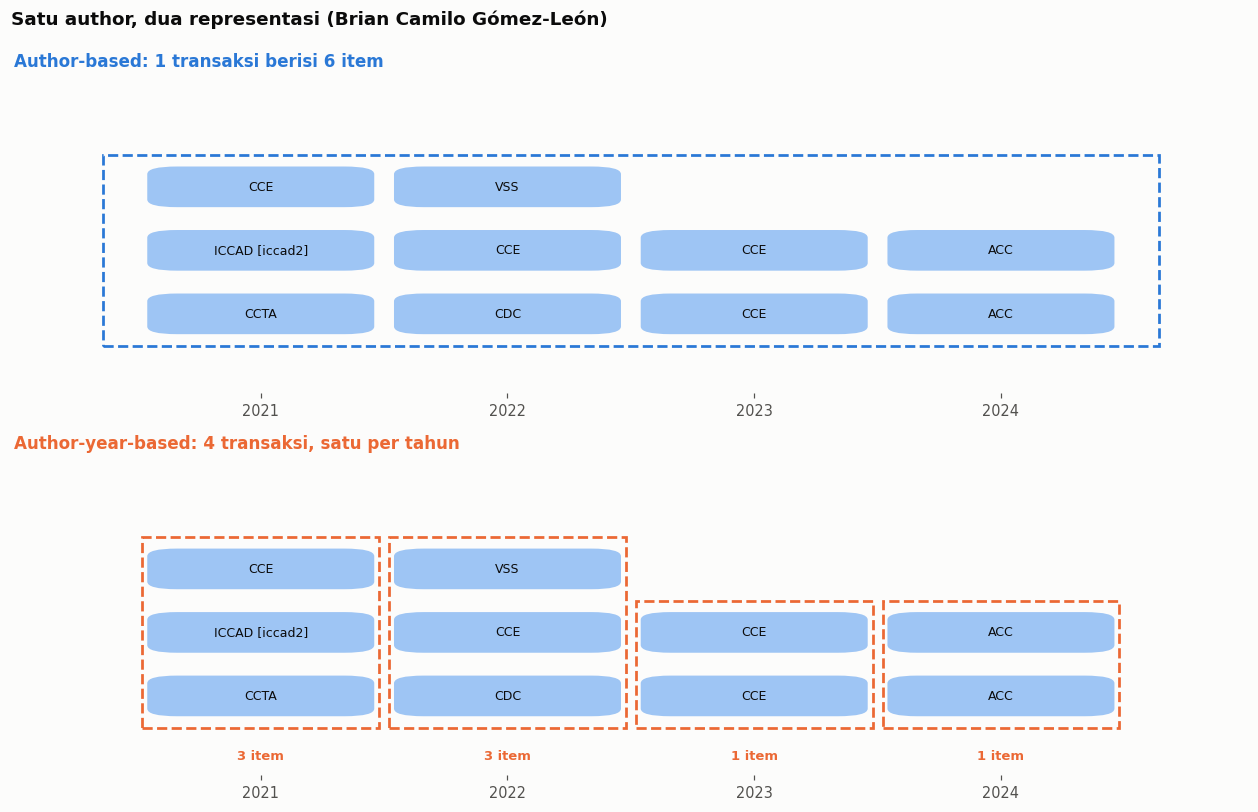

In [12]:
years_present = sorted(example_papers["year"].unique())
year_min, year_max = years_present[0], years_present[-1]
per_year_count = example_papers.groupby("year").size()
per_year_items = example_papers.groupby("year")["venue"].nunique()
max_slot = int(per_year_count.max())
n_example_items = example_papers["venue"].nunique()

def draw_chips(ax):
    slots = {}
    for _, row in example_papers.iterrows():
        year = int(row["year"])
        slot = slots.get(year, 0)
        slots[year] = slot + 1
        ax.add_patch(FancyBboxPatch((year - 0.44, slot - 0.3), 0.88, 0.6, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    fc=CFG.BLUE_LIGHT, ec="none", zorder=3))
        ax.text(year, slot, display_name(row["venue"]), ha="center", va="center", fontsize=8.2, zorder=4)

fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(11.5, 7.4), sharex=True)
for ax in (ax_top, ax_bottom):
    draw_chips(ax)
    ax.set_xlim(year_min - 1, year_max + 1)
    ax.set_ylim(-1.25, max_slot + 0.75)
    ax.set_xticks(years_present)
    ax.tick_params(labelbottom=True, left=False, labelleft=False)
    ax.grid(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_visible(False)

ax_top.add_patch(Rectangle((year_min - 0.64, -0.5), year_max - year_min + 1.28, max_slot, fill=False, ec=CFG.BLUE, lw=1.8, ls="--"))
ax_top.set_title(f"Author-based: 1 transaksi berisi {n_example_items} item", color=CFG.BLUE)

for year in years_present:
    ax_bottom.add_patch(Rectangle((year - 0.48, -0.5), 0.96, int(per_year_count[year]), fill=False, ec=CFG.ORANGE, lw=1.8, ls="--"))
    ax_bottom.text(year, -0.95, f"{int(per_year_items[year])} item", ha="center", va="center", fontsize=8.6, color=CFG.ORANGE, fontweight="bold")
ax_bottom.set_title(f"Author-year-based: {len(years_present)} transaksi, satu per tahun", color=CFG.ORANGE)

fig.suptitle(f"Satu author, dua representasi ({example_author})", x=0.01, ha="left", fontweight="bold", fontsize=12, y=0.99)
fig.tight_layout()
save_fig(fig, "t3_ilustrasi_satu_author.png")

#### Insights

> Author contoh memiliki 10 paper di 6 venue pada 2021-2024. Pada author-based seluruh paper menjadi satu transaksi berisi 6 item. Pada author-year-based paper yang sama menjadi empat transaksi, satu per tahun, dengan 3, 3, 1, dan 1 item.

> Dua hal terlihat dari diagram. Pertama, dua paper pada venue yang sama dalam satu tahun (dua paper CCE pada 2023 dan dua paper ACC pada 2024) hanya menghasilkan satu item, sehingga jumlah paper tidak terbawa ke kedua representasi. Kedua, venue yang dipakai pada tahun berbeda (misalnya CCTA pada 2021 dan ACC pada 2024) hanya berada dalam satu transaksi pada author-based.

## 4.2 Sepuluh Contoh Transaksi Author-Based

Contoh dipilih secara acak per ukuran transaksi (1, 2, 3, 4, 5, 6, 8, 10, 15, dan 25 item), sehingga terlihat mulai dari transaksi paling kecil sampai besar. Item ditulis dengan nama tampilan venue, dan `tid` adalah id transaksi pada tabel panjang.

In [13]:
def short(name):
    return name if len(name) <= 26 else name[:25] + "..."

def pick_examples(sizes, targets, seed):
    rng = np.random.default_rng(seed)
    picked = []
    for target in targets:
        pool = np.flatnonzero(sizes == target)
        if len(pool) == 0:
            pool = np.flatnonzero(sizes == sizes[sizes >= target].min())
        pool = np.setdiff1d(pool, picked)
        picked.append(int(rng.choice(pool)))
    return picked

def examples_table(transactions, index, sizes, targets, with_year):
    rows = []
    for tid in pick_examples(sizes, targets, CFG.SEED):
        assert index.iloc[tid]["tid"] == tid
        names = [short(item_names[i]) for i in sorted(transactions[tid])]
        shown = ", ".join(names[:10]) + (f", ... (+{len(names) - 10} lagi)" if len(names) > 10 else "")
        row = {"tid": tid, "author": index.iloc[tid]["author"]}
        if with_year:
            row["tahun"] = int(index.iloc[tid]["year"])
        row.update({"jumlah_item": len(names), "item": shown})
        rows.append(row)
    return pd.DataFrame(rows)

examples_a = examples_table(tx_a, index_a, sizes_a, [1, 2, 3, 4, 5, 6, 8, 10, 15, 25], with_year=False)
save_table(examples_a, "t3_contoh_transaksi_author.csv", index=False)
examples_a

,tid,author,jumlah_item,item
0,338077,Cheoljoong Park,1,ISSCC
1,1245823,Renann F. Brandao,2,"LATINCOM, Image Perception, Observe..."
2,851248,Satoru Isaka,3,"CASE, ICDL, SMC"
3,466299,Josef Guggemos,4,"CSEDU, DeLFI, LTEC, RiE"
4,389961,Solvita Berzisa,5,"BIR, ICEIS, ICIST, PROFES, SAC"
5,808044,Arun Kumar Thittai,6,"HEALTHINF, EMBC, ISBI, Biomedical Applications i..., SMC, TENCON"
6,64961,Wei Li 0022,8,"ACAI, ECCV, ICDE, ICIP, ICPADS, NSDI, PCM, SIGIR"
7,391158,Thierry J. Chaussalet,10,"BioInfoMed, CBMS, CIBCB, ECMS, HPCC/SmartCity/DSS, ICCS, ICIMTH, INISTA, IEEE Conf. on..."
8,78397,Tomás Masarík,15,"ESA, GD, ICALP, IJCAI, ISAAC, IWOCA, IPEC [iwpec], MFCS, PODC, EC, ... (+5 lagi)"
9,25570,Haibo Zhang,25,"WISA, ADHIP, AIAM, CACRE, CRC, CSPS, DSA, EEET, EIDWT, EMO, ... (+15 lagi)"


#### Insights

> Sepuluh contoh memperlihatkan rentang ukuran transaksi, dari satu item (seorang author yang hanya menerbitkan di ISSCC) sampai 25 item. Transaksi berukuran 4 sampai 8 item umumnya berisi venue dari bidang yang tampak berdekatan, sedangkan contoh 25 item mencampur banyak venue yang tidak seragam dan kemungkinan menggabungkan lebih dari satu orang yang bernama sama (`Haibo Zhang`).

> Nama venue yang kecil dapat panjang karena nama tampilan diambil dari `booktitle` yang paling sering dipakai venue itu. Pada tabel nama yang melebihi 26 karakter dipotong, dan daftar item yang melebihi 10 venue diringkas.

## 4.3 Sepuluh Contoh Transaksi Author-Year-Based

Pengambilan contoh sama, dengan ukuran transaksi 1, 2, 3, 4, 5, 6, 7, 8, 10, dan 14 item. Kolom `tahun` menunjukkan bahwa transaksi dibentuk per pasangan author dan tahun.

In [14]:
examples_ay = examples_table(tx_ay, index_ay, sizes_ay, [1, 2, 3, 4, 5, 6, 7, 8, 10, 14], with_year=True)
save_table(examples_ay, "t3_contoh_transaksi_author_year.csv", index=False)
examples_ay

,tid,author,tahun,jumlah_item,item
0,538906,Hao Chen 0031,2018,1,IJCNN
1,2566923,Dirk Väth,2023,2,"ACL, EACL"
2,1626199,Ayse Keles,2024,3,"COMPSAC, EUVIP, EXPLIMED@ECAI"
3,758263,Rik Eshuis,2015,4,"ICSOC, PRO-VE, NetWordS, OTM"
4,627726,Tom Mens,2018,5,"BENEVOL, CDVE, ICSME, ICSR [icsr], MSR"
5,1534896,Christian Haubelt,2016,6,"ARCS, CPS Data, EICS, MCSoC, SAMOS, WiMob"
6,102172,Lijie Wen 0001,2022,7,"COLING, EMNLP, ICASSP, IPDPS, KDD, NAACL-HLT, SIGIR"
7,711013,Syed Ishtiaque Ahmed,2020,8,"CHI, COMPSAC, CSEE&T, COMPASS, Graphics Interface, ICTD, ICWSM, PDC"
8,136050,Javier Del Ser,2020,10,"CEC, COMPSAC, CW, GECCO Companion, ICCS, IDEAL, IJCNN, ITSC, SOCO, SSCI"
9,44703,Feng Li,2016,14,"CDC, CLSW, GECCO Companion, HCC, ICASSP, ICIC, IGARSS, INFOCOM, ISNN, IJCRS, ... (+4 l..."


#### Insights

> Sepuluh contoh author-year-based berukuran 1 sampai 14 item. Author yang sama dapat muncul pada beberapa transaksi dengan tahun berbeda, sehingga kolom `tahun` menjadi bagian dari identitas transaksi.

> Transaksi besar jauh lebih langka pada representasi ini. Seorang author harus menerbitkan di 14 venue berbeda dalam satu tahun untuk menghasilkan transaksi seperti contoh terakhir, dan hanya 1.261 transaksi (0,03%) yang berisi lebih dari 20 item, dibanding 17.533 transaksi (0,96%) pada author-based.

---

# Statistik Transactional Database (Task 3.3 dan 3.4) <a name="5"></a>

---

Bagian ini menjawab Task 3.3 dan 3.4: jumlah transaksi, jumlah item unik, dan distribusi jumlah item per transaksi. Dua ukuran tambahan dihitung karena langsung memengaruhi Task 4, yaitu frekuensi setiap item terhadap ambang min support dan beban kombinasi yang harus ditanggung algoritma.

## 5.1 Jumlah Transaksi dan Item Unik

Seluruh ukuran dihitung dari bentuk sparse, karena `getnnz` memberi jumlah item per transaksi atau jumlah transaksi per item tanpa loop Python.

In [15]:
def describe(matrix, sizes):
    n, m = matrix.shape
    return {
        "Jumlah transaksi": n,
        "Item unik (muncul pada minimal 1 transaksi)": int((matrix.getnnz(axis=0) > 0).sum()),
        "Pasangan transaksi-item": matrix.nnz,
        "Item per transaksi: minimum": int(sizes.min()),
        "Item per transaksi: median": float(np.median(sizes)),
        "Item per transaksi: rata-rata": float(sizes.mean()),
        "Item per transaksi: persentil 90": float(np.percentile(sizes, 90)),
        "Item per transaksi: persentil 99": float(np.percentile(sizes, 99)),
        "Item per transaksi: maksimum": int(sizes.max()),
        "Transaksi berisi 1 item (%)": float((sizes == 1).mean() * 100),
        "Transaksi berisi minimal 2 item (%)": float((sizes >= 2).mean() * 100),
        "Transaksi berisi minimal 3 item (%)": float((sizes >= 3).mean() * 100),
        "Kepadatan matriks (%)": matrix.nnz / (n * m) * 100,
    }

stats = pd.DataFrame({"Author-based": describe(csr_a, sizes_a), "Author-year-based": describe(csr_ay, sizes_ay)})
save_table(stats, "t3_statistik_database.csv")

largest_a, largest_ay = int(sizes_a.argmax()), int(sizes_ay.argmax())
print(f"Transaksi terbesar author-based      : {index_a.iloc[largest_a]['author']} ({sizes_a[largest_a]} item)")
print(f"Transaksi terbesar author-year-based : {index_ay.iloc[largest_ay]['author']} tahun {index_ay.iloc[largest_ay]['year']} ({sizes_ay[largest_ay]} item)")
stats.round(2)

Transaksi terbesar author-based      : Yang Liu (332 item)
Transaksi terbesar author-year-based : Yang Liu tahun 2024 (85 item)


,Author-based,Author-year-based
Jumlah transaksi,1821757.00,4085594.00
Item unik (muncul pada minimal 1 transaksi),4373.00,4373.00
Pasangan transaksi-item,4853675.00,6497515.00
Item per transaksi: minimum,1.00,1.00
Item per transaksi: median,1.00,1.00
Item per transaksi: rata-rata,2.66,1.59
Item per transaksi: persentil 90,6.00,3.00
Item per transaksi: persentil 99,20.00,7.00
Item per transaksi: maksimum,332.00,85.00
Transaksi berisi 1 item (%),58.40,71.04


#### Insights

> Author-based memiliki 1.821.757 transaksi dan author-year-based 4.085.594, atau 2,24 kali lebih banyak, karena author yang aktif pada beberapa tahun menjadi beberapa transaksi. Kedua database memuat seluruh 4.373 venue sebagai item unik.

> Jumlah pasangan transaksi-item hanya 1,34 kali lebih besar (4.853.675 dibanding 6.497.515) walaupun transaksinya 2,24 kali lebih banyak, sehingga transaksi author-year-based jauh lebih kecil: rata-rata 1,59 item dibanding 2,66, persentil 99 sebesar 7 dibanding 20, dan maksimum 85 dibanding 332. Median kedua database sama, yaitu 1 item.

> Matriks transaksi dan item sangat jarang, dengan kepadatan 0,06% dan 0,04%. Transaksi terbesar pada kedua database berasal dari `Yang Liu` (332 item, dan 85 item pada 2024), yaitu nama umum yang kemungkinan menggabungkan banyak orang, sama seperti temuan pada Task 1.

## 5.2 Distribusi Jumlah Item per Transaksi

Distribusi dibaca dari dua sisi. Stacked bar 100% membandingkan komposisi ukuran transaksi kedua database, bentuk chart komposisi yang dalam panduan Datawrapper mudah dibandingkan antarkategori. Kurva komplementer kumulatif pada skala logaritmik memperlihatkan ekor distribusi, yaitu seberapa banyak transaksi yang berisi sedikitnya sekian item.

In [16]:
bucket_bins = [0, 1, 2, 3, 5, 10, 20, np.inf]
bucket_labels = ["1", "2", "3", "4-5", "6-10", "11-20", ">20"]

dist_count = pd.DataFrame({
    "Author-based": pd.cut(sizes_a, bins=bucket_bins, labels=bucket_labels).value_counts().sort_index(),
    "Author-year-based": pd.cut(sizes_ay, bins=bucket_bins, labels=bucket_labels).value_counts().sort_index(),
})
dist_pct = dist_count / dist_count.sum() * 100
dist_table = pd.concat({"transaksi": dist_count, "persen": dist_pct}, axis=1)
dist_table.index.name = "item per transaksi"
save_table(dist_table, "t3_distribusi_item_per_transaksi.csv")
dist_table.round(2)

transaksi                         persen                  
                   Author-based Author-year-based Author-based Author-year-based
item per transaksi                                                              
1                       1063902           2902494        58.40             71.04
2                        291766            661150        16.02             16.18
3                        140852            253308         7.73              6.20
4-5                      139310            177548         7.65              4.35
6-10                     117066             78662         6.43              1.93
11-20                     51328             11171         2.82              0.27
>20                       17533              1261         0.96              0.03

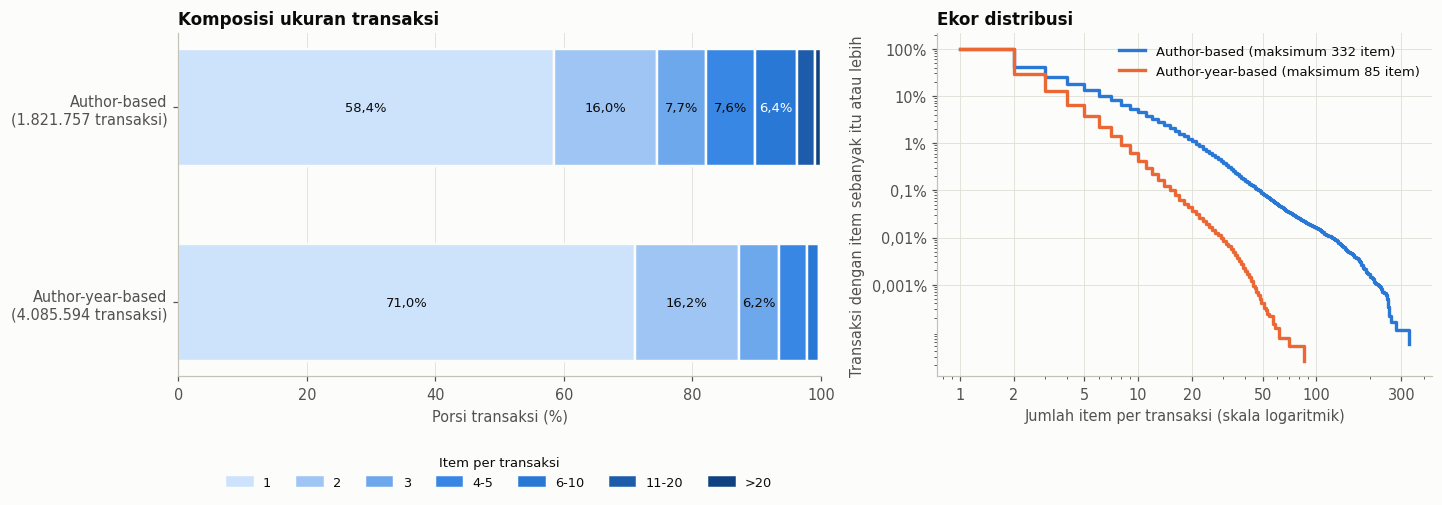

In [17]:
ramp = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281"]
fig, (ax_bar, ax_curve) = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

names = list(dist_pct.columns)[::-1]
for row, name in enumerate(names):
    left = 0.0
    for position, (color, label) in enumerate(zip(ramp, bucket_labels)):
        width = dist_pct.loc[label, name]
        ax_bar.barh(row, width, left=left, color=color, edgecolor=CFG.SURFACE, linewidth=1.6, height=0.6)
        if width >= 5.0:
            ax_bar.text(left + width / 2, row, pct_id(width), ha="center", va="center", fontsize=8.6,
                        color="#ffffff" if position >= 4 else CFG.INK)
        left += width
ax_bar.set_yticks(range(len(names)))
ax_bar.set_yticklabels([f"{n}\n({fmt_id(dist_count[n].sum())} transaksi)" for n in names])
ax_bar.set_xlim(0, 100)
ax_bar.set_xlabel("Porsi transaksi (%)")
ax_bar.grid(axis="y", visible=False)
ax_bar.set_title("Komposisi ukuran transaksi")
ax_bar.legend(handles=[Patch(color=c, label=l) for c, l in zip(ramp, bucket_labels)], title="Item per transaksi",
              loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=7, fontsize=8.4, title_fontsize=8.6)

for sizes, name, color in ((sizes_a, "Author-based", CFG.BLUE), (sizes_ay, "Author-year-based", CFG.ORANGE)):
    values, counts = np.unique(sizes, return_counts=True)
    ccdf = counts[::-1].cumsum()[::-1] / sizes.size * 100
    ax_curve.step(values, ccdf, where="post", color=color, lw=2.2, label=f"{name} (maksimum {int(sizes.max())} item)")
ax_curve.set_xscale("log")
ax_curve.set_yscale("log")
ax_curve.set_xticks([1, 2, 5, 10, 20, 50, 100, 300])
ax_curve.set_xticklabels(["1", "2", "5", "10", "20", "50", "100", "300"])
ax_curve.set_yticks([0.001, 0.01, 0.1, 1, 10, 100])
ax_curve.set_yticklabels(["0,001%", "0,01%", "0,1%", "1%", "10%", "100%"])
ax_curve.set_xlabel("Jumlah item per transaksi (skala logaritmik)")
ax_curve.set_ylabel("Transaksi dengan item sebanyak itu atau lebih")
ax_curve.set_title("Ekor distribusi")
ax_curve.legend(loc="upper right", fontsize=8.6)
fig.tight_layout()
save_fig(fig, "t3_distribusi_item_per_transaksi.png")

#### Insights

> Mayoritas transaksi hanya berisi satu item: 58,4% pada author-based dan 71,0% pada author-year-based. Transaksi satu item tidak dapat membentuk pasangan, sehingga tidak berkontribusi pada itemset berukuran dua ke atas, tetapi tetap masuk penyebut support. Transaksi yang berisi minimal dua item hanya 41,6% dan 29,0%, dan yang berisi minimal tiga item 25,6% dan 12,8%.

> Ekor distribusinya panjang pada author-based: 17.533 transaksi (0,96%) berisi lebih dari 20 item dan yang terbesar 332 item. Pada author-year-based hanya 1.261 transaksi (0,03%) berisi lebih dari 20 item, dan 93,4% transaksi berukuran tiga item atau kurang.

> Karena ekor itu, rata-rata (2,66 dan 1,59) jauh di atas median (1). Distribusi seperti ini memengaruhi pilihan ukuran yang dilaporkan: median menggambarkan transaksi tipikal, sedangkan rata-rata dan persentil atas menggambarkan beban yang ditanggung algoritma.

## 5.3 Frekuensi Item dan Ambang Min Support

Support setiap item dihitung sebagai proporsi transaksi yang memuatnya. Dumbbell chart membandingkan support 15 venue teratas pada kedua database, jenis chart yang dalam panduan Datawrapper cocok untuk membandingkan dua nilai per kategori. Kurva tangga memperlihatkan berapa item yang lolos tiap ambang min support, termasuk empat ambang yang ditetapkan pada Task 4.

In [18]:
support_a = csr_a.getnnz(axis=0) / n_a
support_ay = csr_ay.getnnz(axis=0) / n_ay

item_support = items.assign(support_author=support_a * 100, support_author_year=support_ay * 100,
                            transaksi_author=csr_a.getnnz(axis=0), transaksi_author_year=csr_ay.getnnz(axis=0))
item_support = item_support.sort_values("support_author", ascending=False).reset_index(drop=True)
save_table(item_support.head(50), "t3_support_item_top50.csv", index=False)

ladder = pd.DataFrame({
    "min_support": [f"{s * 100:g}%".replace(".", ",") for s in CFG.MIN_SUPPORTS],
    "min_count_author": [int(np.ceil(s * n_a)) for s in CFG.MIN_SUPPORTS],
    "item_frequent_author": [int((support_a >= s).sum()) for s in CFG.MIN_SUPPORTS],
    "min_count_author_year": [int(np.ceil(s * n_ay)) for s in CFG.MIN_SUPPORTS],
    "item_frequent_author_year": [int((support_ay >= s).sum()) for s in CFG.MIN_SUPPORTS],
})
save_table(ladder, "t3_item_frequent_per_min_support.csv", index=False)
print("Support item tertinggi (%):")
print(item_support.head(8)[["nama", "support_author", "support_author_year"]].round(2).to_string(index=False))
ladder

Support item tertinggi (%):
   nama  support_author  support_author_year
NeurIPS            3.17                 2.34
   CVPR            2.62                 2.07
   AAAI            2.55                 1.72
 ICASSP            2.31                 1.64
   EMBC            2.16                 1.38
    HCI            2.08                 1.34
 IGARSS            1.93                 1.52
  EMNLP            1.86                 1.32


,min_support,min_count_author,item_frequent_author,min_count_author_year,item_frequent_author_year
0,"0,1%",1822,574,4086,298
1,"0,5%",9109,66,20428,42
2,1%,18218,29,40856,17
3,2%,36436,6,81712,2


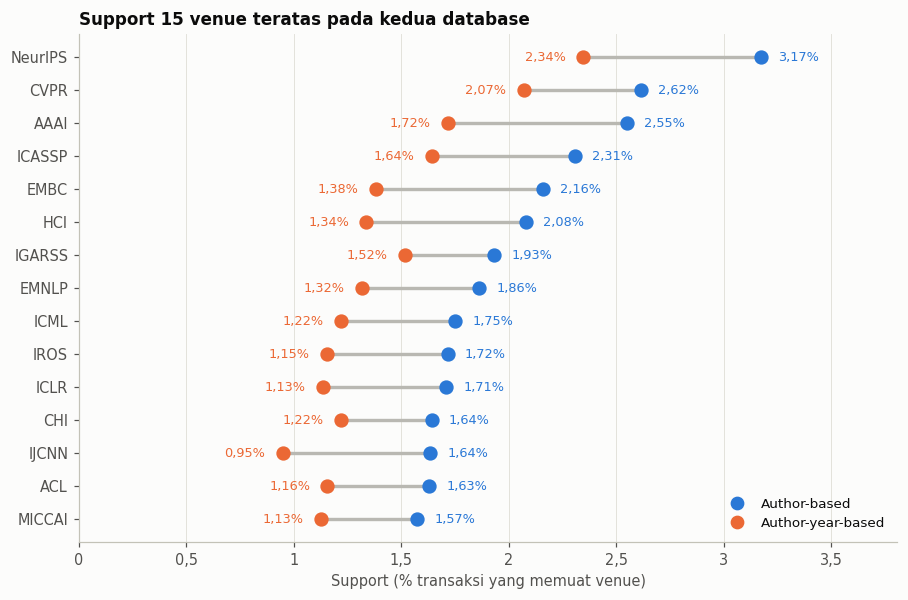

In [19]:
top15 = item_support.head(15).iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.6, 6.0))
for y, row in top15.iterrows():
    ax.plot([row["support_author_year"], row["support_author"]], [y, y], color=CFG.GRAY, lw=2.2, zorder=1)
    ax.scatter(row["support_author"], y, s=70, color=CFG.BLUE, zorder=3)
    ax.scatter(row["support_author_year"], y, s=70, color=CFG.ORANGE, zorder=3)
    ax.text(row["support_author"] + 0.08, y, pct_id(row["support_author"], 2), va="center", fontsize=8.4, color=CFG.BLUE)
    ax.text(row["support_author_year"] - 0.08, y, pct_id(row["support_author_year"], 2), va="center", ha="right", fontsize=8.4, color=CFG.ORANGE)
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15["nama"])
ax.set_xlim(0, top15["support_author"].max() * 1.2)
ax.set_xlabel("Support (% transaksi yang memuat venue)")
id_ticks(ax)
ax.grid(axis="y", visible=False)
ax.set_title("Support 15 venue teratas pada kedua database")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=CFG.BLUE, ms=8, label="Author-based"),
                   Line2D([], [], marker="o", ls="", color=CFG.ORANGE, ms=8, label="Author-year-based")],
          loc="lower right", fontsize=8.8)
save_fig(fig, "t3_support_item_top15.png")

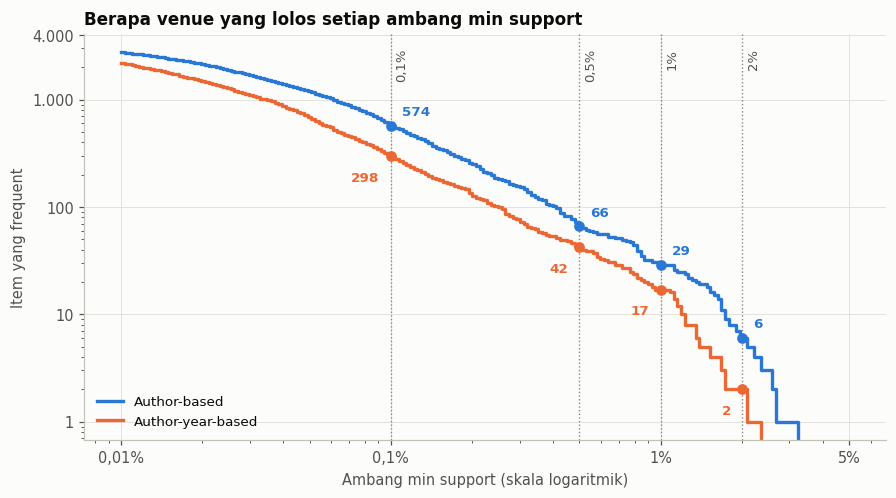

In [20]:
grid = np.logspace(-4, np.log10(0.05), 200)
fig, ax = plt.subplots(figsize=(9.4, 4.8))
for support, name, color in ((support_a, "Author-based", CFG.BLUE), (support_ay, "Author-year-based", CFG.ORANGE)):
    ax.step(grid, [(support >= g).sum() for g in grid], where="post", color=color, lw=2.2, label=name)
for s in CFG.MIN_SUPPORTS:
    ax.axvline(s, color=CFG.MUTED, lw=0.9, ls=":", zorder=1)
    ax.text(s * 1.04, 3000, pct_id(s * 100, 1 if s < 0.01 else 0), fontsize=8.6, color=CFG.INK_2, rotation=90, va="top")
    for support, color, side in ((support_a, CFG.BLUE, "up"), (support_ay, CFG.ORANGE, "down")):
        count = int((support >= s).sum())
        ax.scatter(s, count, s=36, color=color, zorder=4)
        if side == "up":
            ax.text(s * 1.1, count * 1.25, fmt_id(count), fontsize=8.8, color=color, fontweight="bold")
        else:
            ax.text(s / 1.1, count * 0.72, fmt_id(count), fontsize=8.8, color=color, fontweight="bold", ha="right", va="top")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([0.0001, 0.001, 0.01, 0.05])
ax.set_xticklabels(["0,01%", "0,1%", "1%", "5%"])
ax.set_yticks([1, 10, 100, 1000, 4000])
ax.set_yticklabels(["1", "10", "100", "1.000", "4.000"])
ax.set_xlabel("Ambang min support (skala logaritmik)")
ax.set_ylabel("Item yang frequent")
ax.set_title("Berapa venue yang lolos setiap ambang min support")
ax.legend(loc="lower left", fontsize=8.8)
save_fig(fig, "t3_item_frequent_per_min_support.png")

#### Insights

> Venue dengan support tertinggi adalah NeurIPS, sebesar 3,17% pada author-based dan 2,34% pada author-year-based, disusul CVPR (2,62% dan 2,07%) dan AAAI (2,55% dan 1,72%). Support setiap venue lebih rendah pada author-year-based, karena jumlah transaksi yang memuat venue itu naik jauh lebih sedikit daripada penyebutnya, yang naik 2,24 kali.

> Akibatnya ambang yang sama meloloskan lebih sedikit item pada author-year-based: 574 dibanding 298 item pada 0,1%, 66 dibanding 42 pada 0,5%, 29 dibanding 17 pada 1%, dan 6 dibanding 2 pada 2%. Ambang absolutnya juga berbeda, yaitu 1.822 transaksi pada author-based dan 4.086 transaksi pada author-year-based untuk min support 0,1%.

> Hanya 13,1% venue (574 dari 4.373) yang lolos min support 0,1% pada author-based, dan hanya 6 venue yang lolos 2%. Karena pasangan venue teratas pada pratinjau bagian 6.2 hanya memiliki support 1,02%, min support 2% diperkirakan tidak menghasilkan itemset berukuran dua pada Task 4.

## 5.4 Beban Kombinasi

Algoritma yang membangkitkan kombinasi, terutama Apriori, menanggung beban yang tumbuh kuadrat terhadap ukuran transaksi. Beban dihitung sebagai jumlah pasangan item yang dapat dibentuk, pertama pada seluruh item, lalu setelah item di bawah min support dipangkas. Kurva kumulatif memperlihatkan seberapa terkonsentrasi beban itu pada transaksi terbesar.

In [21]:
def pair_load(sizes):
    k = sizes.astype(np.int64)
    return k * (k - 1) // 2

load_a, load_ay = pair_load(sizes_a), pair_load(sizes_ay)

def top_share(load, fraction):
    n_top = max(int(np.ceil(len(load) * fraction)), 1)
    return np.sort(load)[::-1][:n_top].sum() / load.sum() * 100

load_table = pd.DataFrame({
    "Author-based": {"Beban kombinasi total (pasangan)": int(load_a.sum()),
                     "Pasangan dari transaksi terbesar tunggal": int(load_a.max()),
                     "Porsi beban dari 0,1% transaksi terbesar (%)": top_share(load_a, 0.001),
                     "Porsi beban dari 1% transaksi terbesar (%)": top_share(load_a, 0.01),
                     "Porsi beban dari 10% transaksi terbesar (%)": top_share(load_a, 0.10)},
    "Author-year-based": {"Beban kombinasi total (pasangan)": int(load_ay.sum()),
                          "Pasangan dari transaksi terbesar tunggal": int(load_ay.max()),
                          "Porsi beban dari 0,1% transaksi terbesar (%)": top_share(load_ay, 0.001),
                          "Porsi beban dari 1% transaksi terbesar (%)": top_share(load_ay, 0.01),
                          "Porsi beban dari 10% transaksi terbesar (%)": top_share(load_ay, 0.10)},
})
save_table(load_table, "t3_beban_kombinasi.csv")
load_table.round(1)

,Author-based,Author-year-based
Beban kombinasi total (pasangan),21918442.0,5919719.0
Pasangan dari transaksi terbesar tunggal,54946.0,3570.0
"Porsi beban dari 0,1% transaksi terbesar (%)",27.8,14.5
Porsi beban dari 1% transaksi terbesar (%),56.5,39.5
Porsi beban dari 10% transaksi terbesar (%),91.7,83.1


In [22]:
def pruned_workload(matrix, supports, min_support):
    keep = np.flatnonzero(supports >= min_support)
    k = matrix[:, keep].getnnz(axis=1).astype(np.int64)
    return {"item frequent": len(keep), "transaksi dengan minimal 2 item frequent": int((k >= 2).sum()),
            "beban kombinasi setelah pemangkasan": int((k * (k - 1) // 2).sum())}

rows = []
for name, matrix, supports in (("Author-based", csr_a, support_a), ("Author-year-based", csr_ay, support_ay)):
    for s in CFG.MIN_SUPPORTS:
        rows.append({"database": name, "min_support": f"{s * 100:g}%".replace(".", ","), **pruned_workload(matrix, supports, s)})
prune_table = pd.DataFrame(rows)
save_table(prune_table, "t3_beban_setelah_pemangkasan.csv", index=False)
prune_table

,database,min_support,item frequent,transaksi dengan minimal 2 item frequent,beban kombinasi setelah pemangkasan
0,Author-based,"0,1%",574,536543,10214657
1,Author-based,"0,5%",66,239256,2301565
2,Author-based,1%,29,159627,1045018
3,Author-based,2%,6,42103,82850
4,Author-year-based,"0,1%",298,618835,2403502
5,Author-year-based,"0,5%",42,253179,777296
6,Author-year-based,1%,17,134303,300337
7,Author-year-based,2%,2,14485,14485


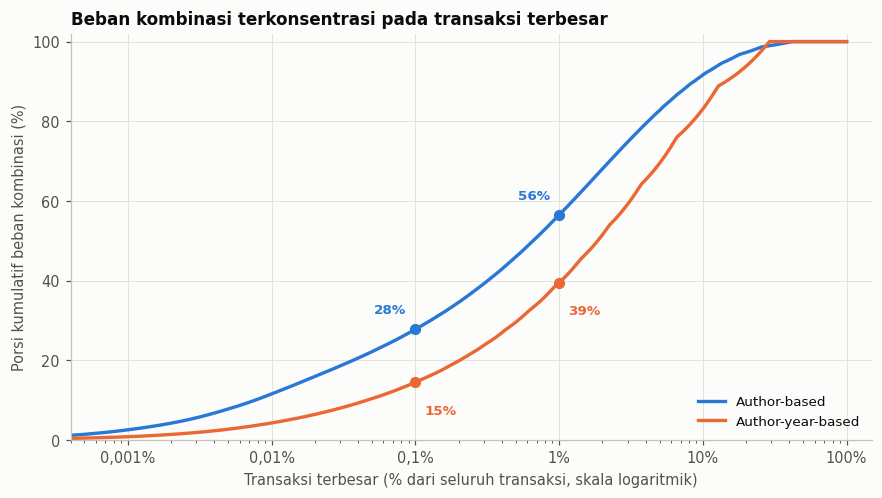

In [23]:
fig, ax = plt.subplots(figsize=(9.4, 4.8))
for load, name, color in ((load_a, "Author-based", CFG.BLUE), (load_ay, "Author-year-based", CFG.ORANGE)):
    ordered = np.sort(load)[::-1]
    cumulative = np.cumsum(ordered) / ordered.sum() * 100
    share_of_transactions = np.arange(1, len(ordered) + 1) / len(ordered) * 100
    ax.plot(share_of_transactions, cumulative, color=color, lw=2.2, label=name)
    for fraction in (0.1, 1.0):
        position = max(int(np.ceil(len(ordered) * fraction / 100)), 1) - 1
        ax.scatter(fraction, cumulative[position], s=40, color=color, zorder=4)
        if color == CFG.BLUE:
            ax.text(fraction / 1.15, cumulative[position] + 4, pct_id(cumulative[position], 0), fontsize=8.8, color=color, fontweight="bold", ha="right")
        else:
            ax.text(fraction * 1.15, cumulative[position] - 8, pct_id(cumulative[position], 0), fontsize=8.8, color=color, fontweight="bold")
ax.set_xscale("log")
ax.set_xlim(0.0004, 150)
ax.set_xticks([0.001, 0.01, 0.1, 1, 10, 100])
ax.set_xticklabels(["0,001%", "0,01%", "0,1%", "1%", "10%", "100%"])
ax.set_ylim(0, 102)
ax.set_xlabel("Transaksi terbesar (% dari seluruh transaksi, skala logaritmik)")
ax.set_ylabel("Porsi kumulatif beban kombinasi (%)")
ax.set_title("Beban kombinasi terkonsentrasi pada transaksi terbesar")
ax.legend(loc="lower right", fontsize=8.8)
save_fig(fig, "t3_konsentrasi_beban_kombinasi.png")

#### Insights

> Beban kombinasi sangat terkonsentrasi pada transaksi terbesar. Pada author-based, total beban 21,9 juta pasangan, dan 0,1% transaksi terbesar (sekitar 1.800 transaksi) menanggung 27,8% beban, 1% terbesar menanggung 56,5%, dan 10% terbesar menanggung 91,7%. Satu transaksi terbesar saja (332 item) menyumbang 54.946 pasangan.

> Author-year-based memiliki beban total 5,9 juta pasangan, atau 3,7 kali lebih rendah, dengan konsentrasi yang lebih rendah (14,5% pada 0,1% transaksi terbesar dan 39,5% pada 1%). Transaksi terbesarnya hanya menyumbang 3.570 pasangan.

> Pemangkasan item di bawah min support memotong beban dengan tajam. Pada author-based, beban turun dari 21,9 juta menjadi 10,2 juta pada 0,1%, 2,3 juta pada 0,5%, 1,0 juta pada 1%, dan 82.850 pada 2%. Pada 0,1% hanya 536.543 transaksi (29,5%) yang masih berisi minimal dua item frequent, dan pada 2% hanya 42.103 transaksi.

> Angka ini adalah ukuran beban kasar, bukan waktu proses. Dugaan bahwa Apriori paling berat pada author-based dengan min support 0,1% (574 item dan 10,2 juta pasangan) perlu dibuktikan lewat pengukuran pada Task 6.

## 5.5 Jumlah Paper di Balik Satu Transaksi

Karena item adalah himpunan venue, beberapa paper dapat berada di balik satu transaksi. Dua paper pada venue yang sama dalam satu tahun, misalnya, hanya menghasilkan satu item. Jumlah paper per transaksi tetap tersimpan pada kolom `n_paper` tabel indeks, sehingga seberapa banyak informasi yang tertelan oleh himpunan dapat diukur untuk kedua representasi.

In [24]:
def paper_stats(n_paper, sizes):
    return {
        "Paper per transaksi: median": float(np.median(n_paper)),
        "Paper per transaksi: rata-rata": float(n_paper.mean()),
        "Paper per transaksi: maksimum": int(n_paper.max()),
        "Transaksi dengan lebih dari 1 paper (%)": float((n_paper > 1).mean() * 100),
        "Transaksi dengan lebih dari 1 paper tetapi hanya 1 item (%)": float(((n_paper > 1) & (sizes == 1)).mean() * 100),
        "Transaksi dengan paper lebih banyak daripada item (%)": float((n_paper > sizes).mean() * 100),
        "Paper yang tidak menambah item baru (%)": float((1 - sizes.sum() / n_paper.sum()) * 100),
    }

paper_table = pd.DataFrame({
    "Author-based": paper_stats(index_a["n_paper"].to_numpy(), sizes_a),
    "Author-year-based": paper_stats(index_ay["n_paper"].to_numpy(), sizes_ay),
})
save_table(paper_table, "t3_paper_per_transaksi.csv")
paper_table.round(2)

,Author-based,Author-year-based
Paper per transaksi: median,1.00,1.00
Paper per transaksi: rata-rata,4.32,1.93
Paper per transaksi: maksimum,725.00,122.00
Transaksi dengan lebih dari 1 paper (%),48.57,35.66
Transaksi dengan lebih dari 1 paper tetapi hanya 1 item (%),6.97,6.70
Transaksi dengan paper lebih banyak daripada item (%),29.92,17.36
Paper yang tidak menambah item baru (%),38.33,17.45


#### Insights

> Jumlah paper di balik satu transaksi tidak sama dengan jumlah itemnya. Pada author-based, 48,6% transaksi dibentuk dari lebih dari satu paper (rata-rata 4,32 paper, maksimum 725), dan pada author-year-based 35,7% (rata-rata 1,93 paper, maksimum 122). Median kedua representasi tetap 1 paper.

> Informasi yang tertelan oleh himpunan lebih besar pada author-based: 38,3% paper tidak menambah item baru karena venue-nya sudah ada pada transaksi, dibanding 17,4% pada author-year-based. Sekitar 7% transaksi pada kedua representasi dibentuk dari beberapa paper pada satu venue yang sama, sehingga hanya berisi satu item.

> Konsekuensinya, support menghitung berapa author (atau pasangan author dan tahun) yang menerbitkan di sebuah venue, bukan berapa paper yang diterbitkan. Author dengan banyak paper di satu venue tidak mendapat bobot lebih pada support. Jumlah paper tetap dapat ditelusuri lewat kolom `n_paper` pada tabel indeks.

---

# Perbandingan dan Analisis (Task 3.5 dan 3.6) <a name="6"></a>

---

Bagian ini menjawab Task 3.5 dan 3.6. Perbedaan kedua representasi dibahas pada tiga tingkat: satu author, ukuran database secara keseluruhan, dan perubahan support pasangan venue. Hasilnya dipakai untuk merumuskan kelebihan dan keterbatasan masing-masing representasi.

## 6.1 Perbedaan pada Satu Author

Author contoh pada bagian 4.1 dipakai kembali. Tabel memperlihatkan isi transaksinya pada kedua representasi dan banyaknya pasangan venue yang dapat dibentuk.

In [25]:
example_tid = int(index_a.index[index_a["author"] == example_author][0])
example_ay = index_ay[index_ay["author"] == example_author].copy()
example_ay["jumlah_item"] = sizes_ay[example_ay["tid"].to_numpy()]
example_ay["item"] = [", ".join(item_names[i] for i in sorted(tx_ay[t])) for t in example_ay["tid"]]
example_ay["pasangan_venue"] = example_ay["jumlah_item"].map(lambda k: comb(int(k), 2))

pairs_author_based = comb(int(sizes_a[example_tid]), 2)
pairs_author_year = int(example_ay["pasangan_venue"].sum())
print(f"Author: {example_author}")
print(f"Author-based      : 1 transaksi, {sizes_a[example_tid]} item, {pairs_author_based} pasangan venue yang dapat muncul bersama")
print(f"Author-year-based : {len(example_ay)} transaksi, {pairs_author_year} pasangan venue yang dapat muncul bersama")
example_ay[["year", "n_paper", "jumlah_item", "pasangan_venue", "item"]].rename(columns={"year": "tahun", "n_paper": "jumlah_paper"})

Author: Brian Camilo Gómez-León
Author-based      : 1 transaksi, 6 item, 15 pasangan venue yang dapat muncul bersama
Author-year-based : 4 transaksi, 6 pasangan venue yang dapat muncul bersama


,tahun,jumlah_paper,jumlah_item,pasangan_venue,item
199569,2022,3,3,3,"CDC, CCE, VSS"
993297,2021,3,3,3,"CCTA, ICCAD [iccad2], CCE"
1565683,2023,2,1,0,CCE
2668311,2024,2,1,0,ACC


#### Insights

> Pada author contoh, author-based menyediakan 15 pasangan venue yang dapat muncul bersama, sedangkan author-year-based hanya 6. Selisih 9 pasangan adalah pasangan lintas tahun (misalnya CCTA pada 2021 dengan ACC pada 2024) yang tidak pernah berada dalam satu transaksi author-year-based.

> Hal ini tidak berlaku sebagai aturan umum: pasangan yang berulang pada beberapa tahun dihitung berulang pada author-year-based, sehingga satu author dapat menyumbang lebih dari satu kali pada support pasangan yang sama. Besarnya kedua efek diukur pada seluruh database di bagian 6.2.

> Tabel yang sama memperlihatkan nasib jumlah paper. Pada 2023 dan 2024, author contoh masing-masing menerbitkan 2 paper, tetapi transaksinya hanya berisi 1 item (CCE dan ACC) karena kedua paper berada pada venue yang sama. Setiap tahun selalu menjadi transaksi terpisah pada author-year-based, sedangkan pada author-based seluruh tahun digabung dan tahun tidak tersimpan pada transaksi.

## 6.2 Perbedaan pada Seluruh Database

Perbandingan seluruh ukuran database sudah dihitung pada bagian 5. Di sini ditambahkan pengaruh representasi terhadap support pasangan venue. Pasangan dihitung hanya antar venue yang support-nya minimal 0,1% pada database author-based (574 item), lalu 10 pasangan teratas author-based dibandingkan dengan support pasangan yang sama pada author-year-based. Ini adalah pratinjau perbandingan, sedangkan pencarian pola sebenarnya dikerjakan pada Task 4.

In [26]:
keep = np.flatnonzero(support_a >= CFG.MIN_SUPPORTS[0])

def cooccurrence(matrix, columns):
    sub = matrix[:, columns].astype(np.float32)
    return (sub.T @ sub).toarray()

co_a, co_ay = cooccurrence(csr_a, keep), cooccurrence(csr_ay, keep)
upper = np.triu_indices(len(keep), 1)
pair_a, pair_ay = co_a[upper], co_ay[upper]

rank_a = (-pair_a).argsort().argsort() + 1
rank_ay = (-pair_ay).argsort().argsort() + 1
top_order = np.argsort(-pair_a)[:10]

pair_table = pd.DataFrame({
    "pasangan venue": [f"{item_names[keep[upper[0][i]]]} + {item_names[keep[upper[1][i]]]}" for i in top_order],
    "transaksi_author": pair_a[top_order].astype(int),
    "support_author_%": pair_a[top_order] / n_a * 100,
    "transaksi_author_year": pair_ay[top_order].astype(int),
    "support_author_year_%": pair_ay[top_order] / n_ay * 100,
    "peringkat_author_year": rank_ay[top_order],
})
pair_table["rasio_support"] = pair_table["support_author_year_%"] / pair_table["support_author_%"]
pair_table["rasio_transaksi"] = pair_table["transaksi_author_year"] / pair_table["transaksi_author"]
save_table(pair_table, "t3_pasangan_teratas_dua_representasi.csv", index=False)

top20_a, top20_ay = set(np.argsort(-pair_a)[:20]), set(np.argsort(-pair_ay)[:20])
both_present = (pair_a > 0) & (pair_ay > 0)
spearman = pd.Series(pair_a[both_present]).corr(pd.Series(pair_ay[both_present]), method="spearman")
print(f"Pasangan yang dianalisis: {len(pair_a):,} | muncul pada author-based: {int((pair_a > 0).sum()):,} | pada author-year-based: {int((pair_ay > 0).sum()):,}")
print(f"Irisan 20 pasangan teratas: {len(top20_a & top20_ay)} dari 20 | korelasi peringkat (Spearman) pasangan yang muncul di keduanya: {spearman:.3f}")
print(f"Median rasio support (author-year / author) pada 100 pasangan teratas author-based: {np.median(pair_ay[np.argsort(-pair_a)[:100]] / n_ay / (pair_a[np.argsort(-pair_a)[:100]] / n_a)):.2f}")
top100 = np.argsort(-pair_a)[:100]
print(f"Median rasio jumlah transaksi (author-year / author) pada 100 pasangan teratas: {np.median(pair_ay[top100] / pair_a[top100]):.2f}")
print(f"Pasangan dengan jumlah transaksi author-year minimal sama dengan author-based: {int((pair_ay[top100] >= pair_a[top100]).sum())} dari 100")
pair_table.round(2)

Pasangan yang dianalisis: 164,451 | muncul pada author-based: 157,402 | pada author-year-based: 120,937
Irisan 20 pasangan teratas: 18 dari 20 | korelasi peringkat (Spearman) pasangan yang muncul di keduanya: 0.892
Median rasio support (author-year / author) pada 100 pasangan teratas author-based: 0.29
Median rasio jumlah transaksi (author-year / author) pada 100 pasangan teratas: 0.65
Pasangan dengan jumlah transaksi author-year minimal sama dengan author-based: 4 dari 100


,pasangan venue,transaksi_author,support_author_%,transaksi_author_year,support_author_year_%,peringkat_author_year,rasio_support,rasio_transaksi
0,ICML + NeurIPS,18503,1.02,17719,0.43,1,0.43,0.96
1,ICLR + NeurIPS,17852,0.98,16438,0.40,2,0.41,0.92
2,AAAI + NeurIPS,15973,0.88,12281,0.30,6,0.34,0.77
3,CVPR + NeurIPS,15640,0.86,14485,0.35,4,0.41,0.93
4,CVPR + ICCV,15441,0.85,12359,0.30,5,0.36,0.80
5,ACL + EMNLP,14557,0.80,15232,0.37,3,0.47,1.05
6,CVPR + ECCV,13752,0.75,9978,0.24,9,0.32,0.73
7,ICLR + ICML,12947,0.71,11110,0.27,7,0.38,0.86
8,AAAI + CVPR,12169,0.67,9958,0.24,10,0.36,0.82
9,ICRA + IROS,11860,0.65,9502,0.23,11,0.36,0.80


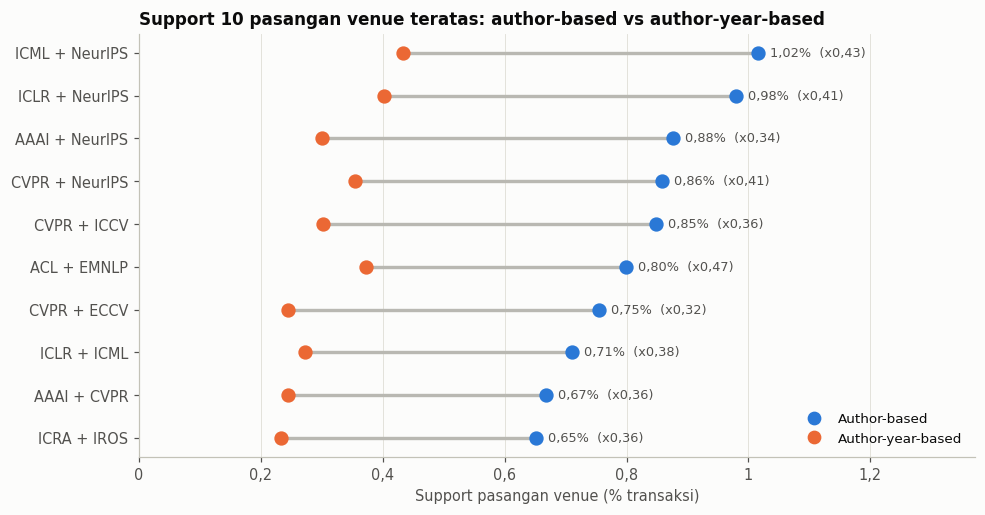

In [27]:
shown = pair_table.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.8, 5.0))
for y, row in shown.iterrows():
    ax.plot([row["support_author_year_%"], row["support_author_%"]], [y, y], color=CFG.GRAY, lw=2.2, zorder=1)
    ax.scatter(row["support_author_%"], y, s=70, color=CFG.BLUE, zorder=3)
    ax.scatter(row["support_author_year_%"], y, s=70, color=CFG.ORANGE, zorder=3)
    ax.text(row["support_author_%"] + 0.02, y, f"{pct_id(row['support_author_%'], 2)}  (x{fmt_id(row['rasio_support'], 2)})",
            va="center", fontsize=8.4, color=CFG.INK_2)
ax.set_yticks(range(len(shown)))
ax.set_yticklabels(shown["pasangan venue"])
ax.set_xlim(0, shown["support_author_%"].max() * 1.35)
ax.set_xlabel("Support pasangan venue (% transaksi)")
id_ticks(ax)
ax.grid(axis="y", visible=False)
ax.set_title("Support 10 pasangan venue teratas: author-based vs author-year-based")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=CFG.BLUE, ms=8, label="Author-based"),
                   Line2D([], [], marker="o", ls="", color=CFG.ORANGE, ms=8, label="Author-year-based")],
          loc="lower right", fontsize=8.8)
save_fig(fig, "t3_support_pasangan_dua_representasi.png")

Satu kasus khusus diuji karena langsung berkaitan dengan dimensi waktu. ICCV dan ECCV adalah konferensi dua tahunan yang diselenggarakan pada tahun yang berselang, sehingga seorang author hampir tidak mungkin menerbitkan di keduanya pada tahun yang sama. Tabel memperlihatkan jumlah transaksi author-year-based per tahun yang memuat masing-masing venue, lalu jumlah transaksi yang memuat keduanya pada kedua database.

In [28]:
biennial = ["iccv", "eccv"]
biennial_ids = [item_of[v] for v in biennial]
years_range = list(range(2015, 2026))
activity = {}
for venue, item in zip(biennial, biennial_ids):
    rows = csr_ay[:, item].nonzero()[0]
    activity[display_name(venue)] = np.bincount(index_ay["year"].to_numpy()[rows] - 2015, minlength=len(years_range))
biennial_table = pd.DataFrame(activity, index=years_range).T

both_a = int((csr_a[:, biennial_ids].getnnz(axis=1) == 2).sum())
both_ay = int((csr_ay[:, biennial_ids].getnnz(axis=1) == 2).sum())
single_a = [int(csr_a[:, i].getnnz()) for i in biennial_ids]
print(f"Transaksi author-based yang memuat ICCV: {single_a[0]:,} | ECCV: {single_a[1]:,} | keduanya: {both_a:,}")
print(f"Transaksi author-year-based yang memuat keduanya: {both_ay:,}")
biennial_table

Transaksi author-based yang memuat ICCV: 27,077 | ECCV: 23,591 | keduanya: 10,051
Transaksi author-year-based yang memuat keduanya: 0


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ICCV,1543,0,1959,0,3627,0,5971,0,8439,0,15260
ECCV,0,1986,0,3770,0,6001,0,7869,0,11930,0


#### Insights

> Dari 164.451 pasangan venue di antara 574 venue yang support-nya minimal 0,1% pada author-based, 157.402 pasangan muncul sedikitnya sekali pada author-based dan 120.937 pada author-year-based. Author-year-based karena itu kehilangan sekitar 23% pasangan, yaitu pasangan yang hanya terjadi lintas tahun dan tidak pernah berada dalam satu transaksi.

> Support pasangan teratas turun tajam: median 0,29 kali support author-based pada 100 pasangan teratas. Penurunan itu hampir seluruhnya berasal dari penyebut. Jumlah transaksi yang memuat pasangan hanya turun ke 0,65 kali, sedangkan jumlah transaksi database naik 2,24 kali (0,65 dibagi 2,24 menghasilkan sekitar 0,29). Ambang min support yang sama berarti ambang absolut yang lebih tinggi pada author-year-based.

> Urutan pasangan relatif terjaga: 18 dari 20 pasangan teratas sama pada kedua database, dengan korelasi peringkat Spearman 0,892 pada pasangan yang muncul di keduanya. ICML dan NeurIPS tetap peringkat 1, dan ICLR dengan NeurIPS tetap peringkat 2.

> Perubahan peringkat memperlihatkan efek representasi. ACL dengan EMNLP naik dari peringkat 6 ke 3, dan jumlah transaksinya bahkan 1,05 kali author-based, karena author yang konsisten menerbitkan di keduanya setiap tahun dihitung berulang. Hanya 4 dari 100 pasangan teratas yang mencapai rasio sekurangnya 1. Sebaliknya AAAI dengan NeurIPS turun dari peringkat 3 ke 6, dan ICRA dengan IROS bergeser dari peringkat 10 ke 11.

> Kasus paling ekstrem adalah konferensi dua tahunan yang berselang tahun. ICCV (tahun ganjil) dan ECCV (tahun genap) dimuat bersama oleh 10.051 transaksi author-based, tetapi oleh nol transaksi author-year-based, karena keduanya tidak pernah diselenggarakan pada tahun yang sama. Asosiasi nyata antara dua komunitas ini tidak dapat terdeteksi sama sekali pada author-year-based.

## 6.3 Kelebihan dan Keterbatasan untuk Frequent Pattern Mining (Task 3.6)

Kelebihan dan keterbatasan dirumuskan dari hasil pada bagian 3 sampai 6, bukan dari teori semata. Angka dalam tabel berasal dari output di atas.

| | Author-based | Author-year-based |
|---|---|---|
| Arti "muncul bersama" | Author pernah menerbitkan di kedua venue pada 2015-2025 | Author menerbitkan di kedua venue pada tahun yang sama |
| **Kelebihan** | 1. Transaksi lebih kaya: 41,6% berisi minimal 2 item, rata-rata 2,66 item.<br>2. Support lebih tinggi sehingga lebih banyak item dan pola lolos ambang yang sama (574 item pada 0,1% dibanding 298).<br>3. Satu author satu transaksi, sehingga transaksi saling bebas dan mudah ditafsirkan sebagai profil venue seorang author.<br>4. Menangkap asosiasi lintas waktu, termasuk konferensi dua tahunan yang berselang (ICCV dan ECCV: 10.051 transaksi). | 1. Mengikat kemunculan bersama pada waktu yang sama, sehingga mengurangi asosiasi semu akibat perpindahan minat dari tahun ke tahun.<br>2. Transaksi kecil dan ekor pendek (maksimum 85 item), sehingga beban kombinasi 3,7 kali lebih rendah (5,9 juta dibanding 21,9 juta pasangan).<br>3. Memiliki dimensi tahun, sehingga dapat dipotong per periode untuk analisis temporal.<br>4. Author yang konsisten diperhitungkan berulang, sehingga mengukur kebiasaan publikasi (contoh ACL dan EMNLP). |
| **Keterbatasan** | 1. Tidak ada dimensi waktu: venue yang dipakai pada fase berbeda dianggap muncul bersama.<br>2. Beban terkonsentrasi pada transaksi besar (0,1% transaksi menanggung 27,8% beban), dan nama umum yang menggabungkan banyak orang (`Yang Liu`, 332 item) menghasilkan asosiasi semu.<br>3. 58,4% transaksi hanya satu item dan tidak berkontribusi pada pasangan.<br>4. Tidak dapat dipakai langsung untuk membandingkan perubahan antarperiode. | 1. 71,0% transaksi berisi satu item dan hanya 29,0% yang dapat membentuk pasangan, sehingga support pasangan jauh lebih rendah (median 0,29 kali) dan lebih sedikit pola lolos ambang (2 item pada 2%).<br>2. Transaksi tidak saling bebas: author aktif muncul pada banyak transaksi dan mendapat bobot lebih besar.<br>3. Kehilangan pasangan lintas tahun (sekitar 23% pasangan tidak pernah muncul), dan konferensi dua tahunan berselang tidak dapat berpasangan (ICCV dan ECCV: 0 transaksi).<br>4. Data 2025 tidak lengkap sehingga transaksi periode terakhir bias. |

#### Insights

> Kedua representasi menjawab pertanyaan yang berbeda. Author-based menjawab venue apa saja yang dipilih oleh author yang sama selama 11 tahun, sedangkan author-year-based menjawab venue apa yang dipilih bersamaan oleh author yang sama pada tahun yang sama. Keduanya valid, dan pilihan bergantung pada pertanyaan analisis.

> Untuk pertanyaan Task 4, yaitu kombinasi konferensi yang sering muncul bersama dalam riwayat publikasi author, author-based lebih sesuai karena riwayat yang dimaksud mencakup seluruh periode. Author-year-based lebih sesuai untuk analisis temporal pada Bagian E, karena tahun menjadi bagian dari transaksi dan periode dapat dipisahkan.

> Pada kedua representasi, mayoritas transaksi (58,4% dan 71,0%) hanya berisi satu item dan tidak membentuk pasangan, sedangkan sebagian kecil transaksi besar menanggung sebagian besar beban kombinasi. Dua hal ini menjadi catatan penting bagi Task 4: min support dihitung terhadap seluruh transaksi, dan waktu proses akan didominasi oleh transaksi besar.

---

# Ringkasan dan Langkah Berikutnya <a name="7"></a>

---

Ringkasan berikut merangkum jawaban Task 3, berkas yang dihasilkan untuk notebook berikutnya, dan rencana notebook per tahap.

## 7.1 Ringkasan Hasil

| Task | Pertanyaan | Hasil utama | Bukti |
|---|---|---|---|
| 3.1 | Membentuk dua database | Author-based dan author-year-based, dibentuk dari satu tabel panjang dan diverifikasi identik pada bentuk horizontal dan sparse | 3.1 sampai 3.3 |
| 3.2 | Sepuluh contoh transaksi | Sepuluh contoh per database, ukuran 1 sampai 25 item (author-based) dan 1 sampai 14 item (author-year-based) | 4.2 dan 4.3 |
| 3.3 | Jumlah transaksi | 1.821.757 (author-based) dan 4.085.594 (author-year-based) | 5.1 |
| 3.4 | Item unik dan distribusi | 4.373 item unik pada keduanya. Median 1 item, rata-rata 2,66 dan 1,59, maksimum 332 dan 85. Transaksi satu item 58,4% dan 71,0% | 5.1 dan 5.2 |
| 3.5 | Perbedaan kedua representasi | Author-year-based memiliki 2,24 kali lebih banyak transaksi yang lebih kecil, support pasangan median 0,29 kali, kehilangan sekitar 23% pasangan, dan tidak dapat memuat pasangan konferensi berselang tahun | 6.1 dan 6.2 |
| 3.6 | Kelebihan dan keterbatasan | Tabel pada 6.3. Author-based sesuai untuk Task 4, author-year-based untuk analisis temporal | 6.3 |

## 7.2 Berkas yang Dihasilkan

Berkas berikut berada di `data/processed/` dan dibaca oleh notebook Apriori, FP-Growth, dan notebook berikutnya. Tabel panjang adalah sumber kebenaran, dan bentuk horizontal serta sparse dibentuk ulang darinya dengan fungsi `to_horizontal` dan `to_sparse` pada bagian 3.3.

| Berkas | Isi |
|---|---|
| `tx_items.csv` | Pemetaan `item_id` ke `venue` dan nama tampilan |
| `tx_author.parquet` | Tabel panjang `(tid, item)` database author-based |
| `tx_author_index.parquet` | Pemetaan `tid` ke `author` |
| `tx_author_year.parquet` | Tabel panjang `(tid, item)` database author-year-based |
| `tx_author_year_index.parquet` | Pemetaan `tid` ke `author` dan `year` |

## 7.3 Rencana Notebook Berikutnya

Setiap tahap dikerjakan pada notebook tersendiri agar mudah diperiksa dan diulang.

| Notebook | Isi | Masukan |
|---|---|---|
| `00_extract` | Ekstraksi XML | `dblp.xml.gz` |
| `01_eda` | Task 1 dan Task 2 | `inproceedings_raw.parquet` |
| `02_transactions` | Task 3 (notebook ini) | `paper_author.parquet` |
| `03_apriori` | Apriori pada author-based, min support 0,1%, 0,5%, 1%, 2% | `tx_author.parquet` |
| `04_fpgrowth` | FP-Growth pada database yang sama, validasi dengan `mlxtend` | `tx_author.parquet` |
| `05_rules` | Association rules dengan min confidence 50% | itemset dari notebook 03 dan 04 |
| `06_performance` | Perbandingan Apriori dan FP-Growth | hasil notebook 03 dan 04 |
| `07_temporal` | Analisis temporal pada author-year-based, empat periode | `tx_author_year.parquet` |

Aturan pengukuran waktu pada notebook 03, 04, dan 06: waktu memuat data dan membentuk database horizontal tidak dihitung. Waktu Apriori mencakup seluruh pemindaian dan pembangkitan kandidat. Waktu FP-Growth mencakup pembentukan FP-tree dan penambangan rekursifnya, dan keduanya dilaporkan terpisah.